# Kalshi trading volume

Where did trading activity concentrate, and how do forecast comparisons change when the most heavily traded markets count more? This analysis covers the November 2, 2026 Senate forecast snapshot. Volume measures cumulative trading activity through capture. It describes where activity accumulated across these markets. Capital invested and liquidity require other evidence, such as open interest or contemporaneous bid-ask spreads.

Trading volume is in U.S. dollars. The data report one cumulative total per race, so the amount traded on each outcome is unavailable. See the [analysis plan](../docs/analysis-plan.md) and [data guide](../data/README.md).

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from congress_scorecard import load_context
from congress_scorecard.chart_lint import lint_chart
from congress_scorecard.data import sha256
from congress_scorecard.plotting import bar_chart, graphics_assets, make_canvas, save_chart, source_colors
from congress_scorecard.runtime import write_manifest
from congress_scorecard.scoring import brier_loss, match_sample, probability_score

PART = "03_kalshi_trading_volume"
VOLUME_UNITS = "USD"
VOLUME_CUTOFF = 250_000
VOLUME_UNIT_EVIDENCE = "Project owner confirmation, November 9, 2026"
STATE_NAMES = {
    "AK": "Alaska", "AL": "Alabama", "AR": "Arkansas", "CO": "Colorado",
    "DE": "Delaware", "FL": "Florida", "GA": "Georgia", "IA": "Iowa",
    "ID": "Idaho", "IL": "Illinois", "KS": "Kansas", "KY": "Kentucky",
    "LA": "Louisiana", "MA": "Massachusetts", "ME": "Maine", "MI": "Michigan",
    "MN": "Minnesota", "MS": "Mississippi", "MT": "Montana", "NC": "North Carolina",
    "NE": "Nebraska", "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico",
    "OH": "Ohio", "OK": "Oklahoma", "OR": "Oregon", "RI": "Rhode Island",
    "SC": "South Carolina", "SD": "South Dakota", "TN": "Tennessee", "TX": "Texas",
    "VA": "Virginia", "WV": "West Virginia", "WY": "Wyoming",
}

def state_name(race):
    return STATE_NAMES[race.split("-")[0]]
ctx = load_context(PART)
inputs = ctx.inputs
senate = inputs.senate
snapshot = inputs.snapshot_id
synthetic = inputs.manifest["synthetic"]
coverage = inputs.diagnostics["verified_calls"]
total = senate.volume.sum()
ranked = senate[["volume"]].sort_index().sort_values("volume", ascending=False, kind="stable")
ranked["share"] = ranked.volume / total
ranked["rank"] = np.arange(1, len(ranked) + 1)
colors = source_colors()
figures = []

print(f"Forecast snapshot: November 2, 2026 | Results snapshot: {snapshot}")
print(f"Senate results timestamp: {inputs.manifest['senate_timestamp'] or 'fixture identifier only'}")
print(f"Eligible Senate calls: {coverage}/{len(senate)} | Synthetic fixture: {synthetic}")
print("Outcome results are illustrative." if synthetic else "Outcome results are preliminary.")
for qualification in inputs.diagnostics["qualifications"]:
    if not qualification.startswith("Currency volume labels and dollar cutoff unavailable"):
        print(qualification)
print(f"Volume units: {VOLUME_UNITS}. {VOLUME_UNIT_EVIDENCE}.")

def save_table(name, rows):
    rows.assign(snapshot=snapshot, synthetic=synthetic, volume_units=VOLUME_UNITS).to_csv(ctx.tables_dir / f"{name}.csv")

def export(canvas, name, rows):
    png = save_chart(canvas, name, out_dir=ctx.figures_dir)["png"]
    data = f"plot_{name}"
    save_table(data, rows)
    lint = lint_chart(canvas, png)
    write_manifest(ctx.tables_dir / f"lint_{name}.json", lint)
    if not lint["passed"]:
        raise ValueError(lint["failures"])
    figures.append({"image": png.name, "data": f"{data}.csv", "lint_passed": True})
    display(Image(filename=str(png), width=960))

def volume_bars(name, title, subtitle, rows, highlight=None):
    source = f"Source: Kalshi snapshot, Nov. 2, 2026. Total trading volume: ${total:,.0f}."
    canvas = make_canvas(title, subtitle=subtitle, source=source)
    labels = rows["state"] if "state" in rows else rows.index
    ax = bar_chart(canvas, labels, 100 * rows.share, sort=False, value_fmt="{:.1f}%",
                   colors={highlight: "#EEEAAC"} if highlight else None)
    np.testing.assert_allclose([bar.get_width() for bar in ax.patches], 100 * rows.share)
    export(canvas, name, rows)

def volume_groups(category, order):
    groups = senate.volume.groupby(category).agg(races="size", volume="sum")
    groups = groups.reindex(order, fill_value=0)
    groups["share"] = groups.volume / total
    assert groups.races.sum() == len(senate)
    assert np.isclose(groups.volume.sum(), total) and np.isclose(groups.share.sum(), 1)
    return groups

leader = ranked.index[0]
print(f"{state_name(leader)} accounted for {ranked.share.iloc[0]:.1%} of the recorded total. "
      f"The three largest markets accounted for {ranked.share.iloc[:3].sum():.1%}.")

Forecast snapshot: November 2, 2026 | Results snapshot: ddhq-20261112-manual
Senate results timestamp: 2026-11-12T12:24:00-05:00
Eligible Senate calls: 34/35 | Synthetic fixture: False
Outcome results are preliminary.
Preliminary results; eligibility varies by metric.
Kalshi recorded probabilities provisionally approved despite unverified price measures and KY contract URL.
Independent caucus evidence contradicts plan assumption; caucus seat/control reporting withheld.
Mixed-vintage Senate snapshot: only MS-SEN refreshed. The other 34 rows retain November 4 vote/call data and evidence. snapshot_timestamp denotes the assembled component, not a new capture for every row.
MS-SEN DDHQ call is November 11 at 18:28 EST; displayed vote update November 12 at 12:24 EST. Minute-precision timestamps use zero seconds.
MS reporting is displayed as >95%; numeric percent_reporting withheld to avoid asserting an exact estimate. Vote shares remain incomplete and ineligible for share scoring.
House cont

## 1. Volume by Cook rating

Combine Democratic and Republican directions within each rating. This summary uses every recorded Senate forecast.

,races,volume,share
Cook_Rating,,,
Toss-Up,7,160790744.0,0.757864
Lean,4,26591445.0,0.125335
Likely,4,17300277.0,0.081542
Solid,20,7480565.0,0.035259


Non-Solid races accounted for 96.5% of recorded volume.


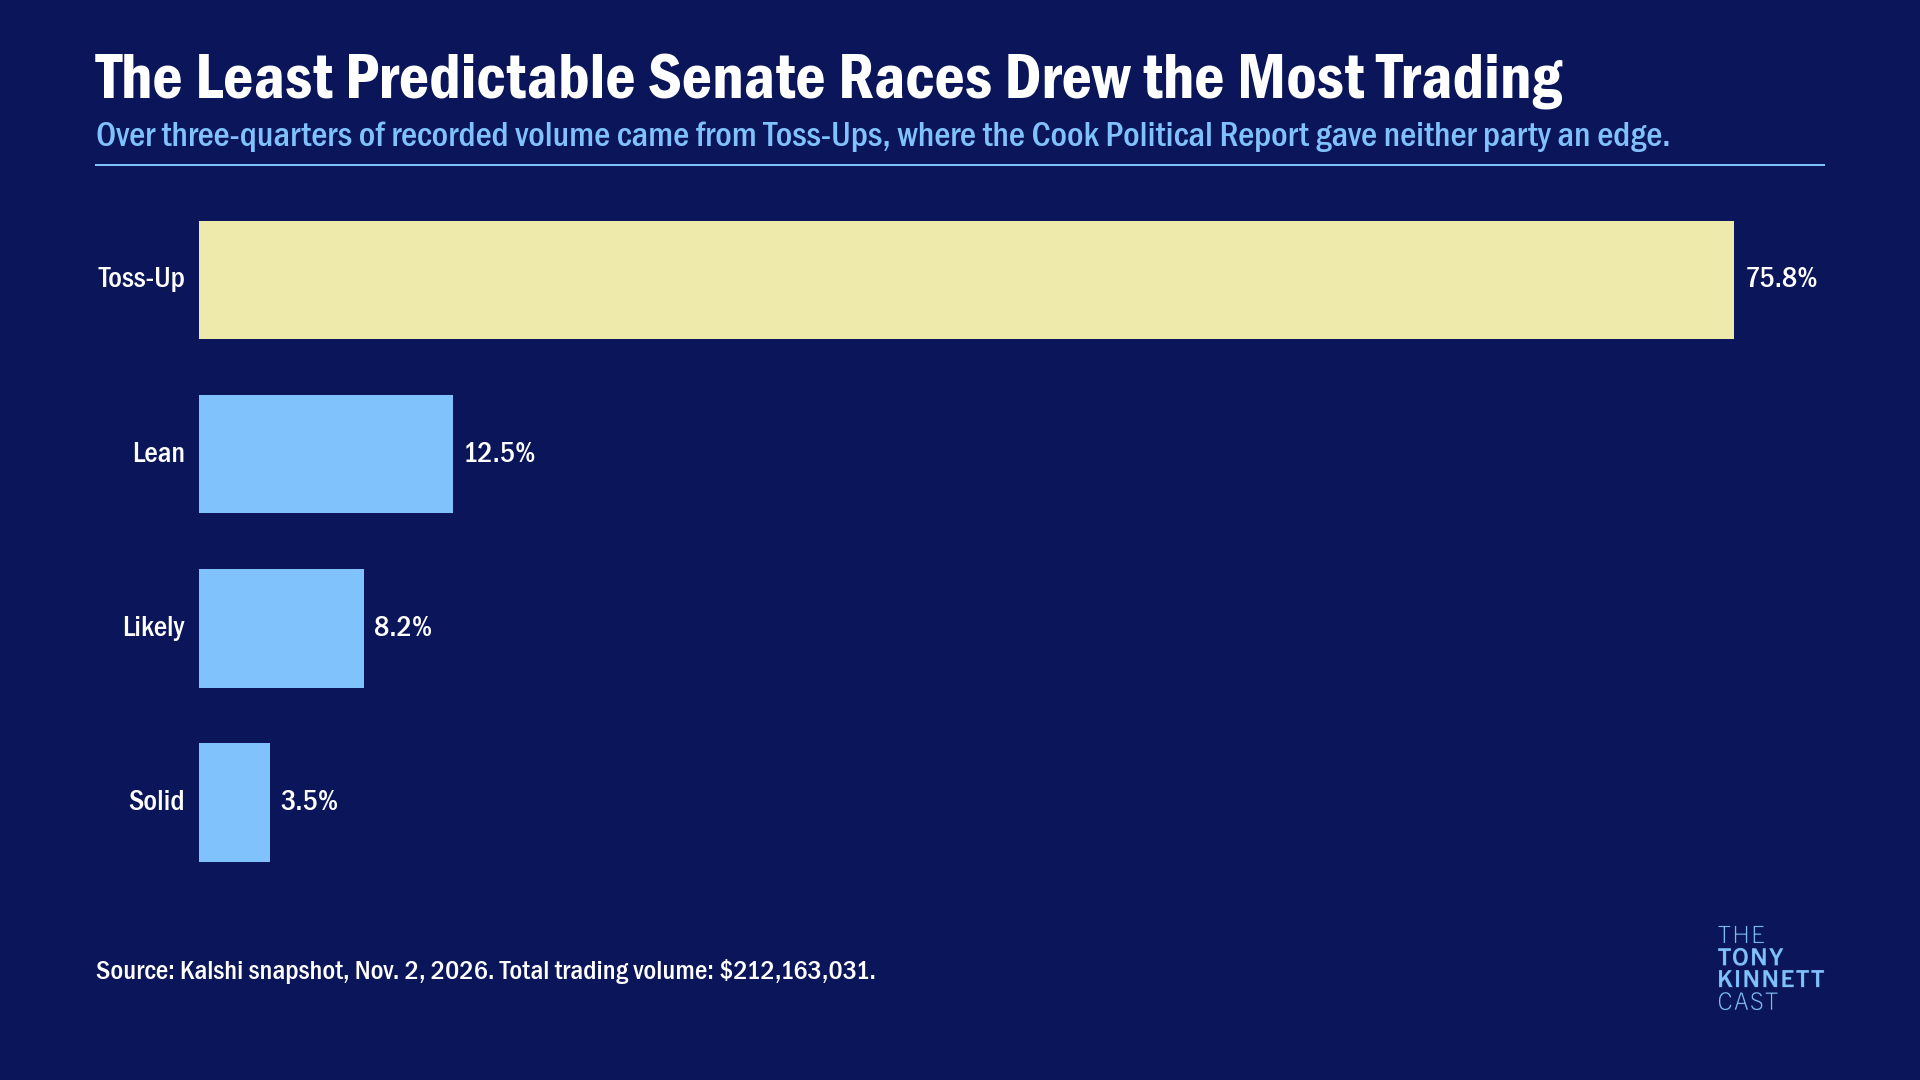

In [2]:
cook_order = ["Toss-Up", "Lean", "Likely", "Solid"]
ratings = senate.Cook_Rating.str.split().str[0]
cook = volume_groups(ratings, cook_order)
non_solid = cook.loc[cook_order[:3], "share"].sum()
display(cook)
print(f"Non-Solid races accounted for {non_solid:.1%} of recorded volume.")
volume_bars("01-cook-ratings", "The Least Predictable Senate Races Drew the Most Trading",
            "Over three-quarters of recorded volume came from Toss-Ups, where the Cook Political Report gave neither party an edge.",
            cook, cook.share.idxmax())

## 2. Volume concentration

The bars show the ten largest markets as shares of all 35 races. The table ranks the full field, with ties ordered by race ID.

,volume,share,rank
state,,,
Texas,76421319.0,0.360201,1
Michigan,26655798.0,0.125638,2
Maine,19737871.0,0.093032,3
Ohio,10462186.0,0.049312,4
Iowa,10343198.0,0.048751,5
South Carolina,9906147.0,0.046691,6
Kansas,9725912.0,0.045842,7
Alaska,7444460.0,0.035088,8
Minnesota,7203326.0,0.033952,9


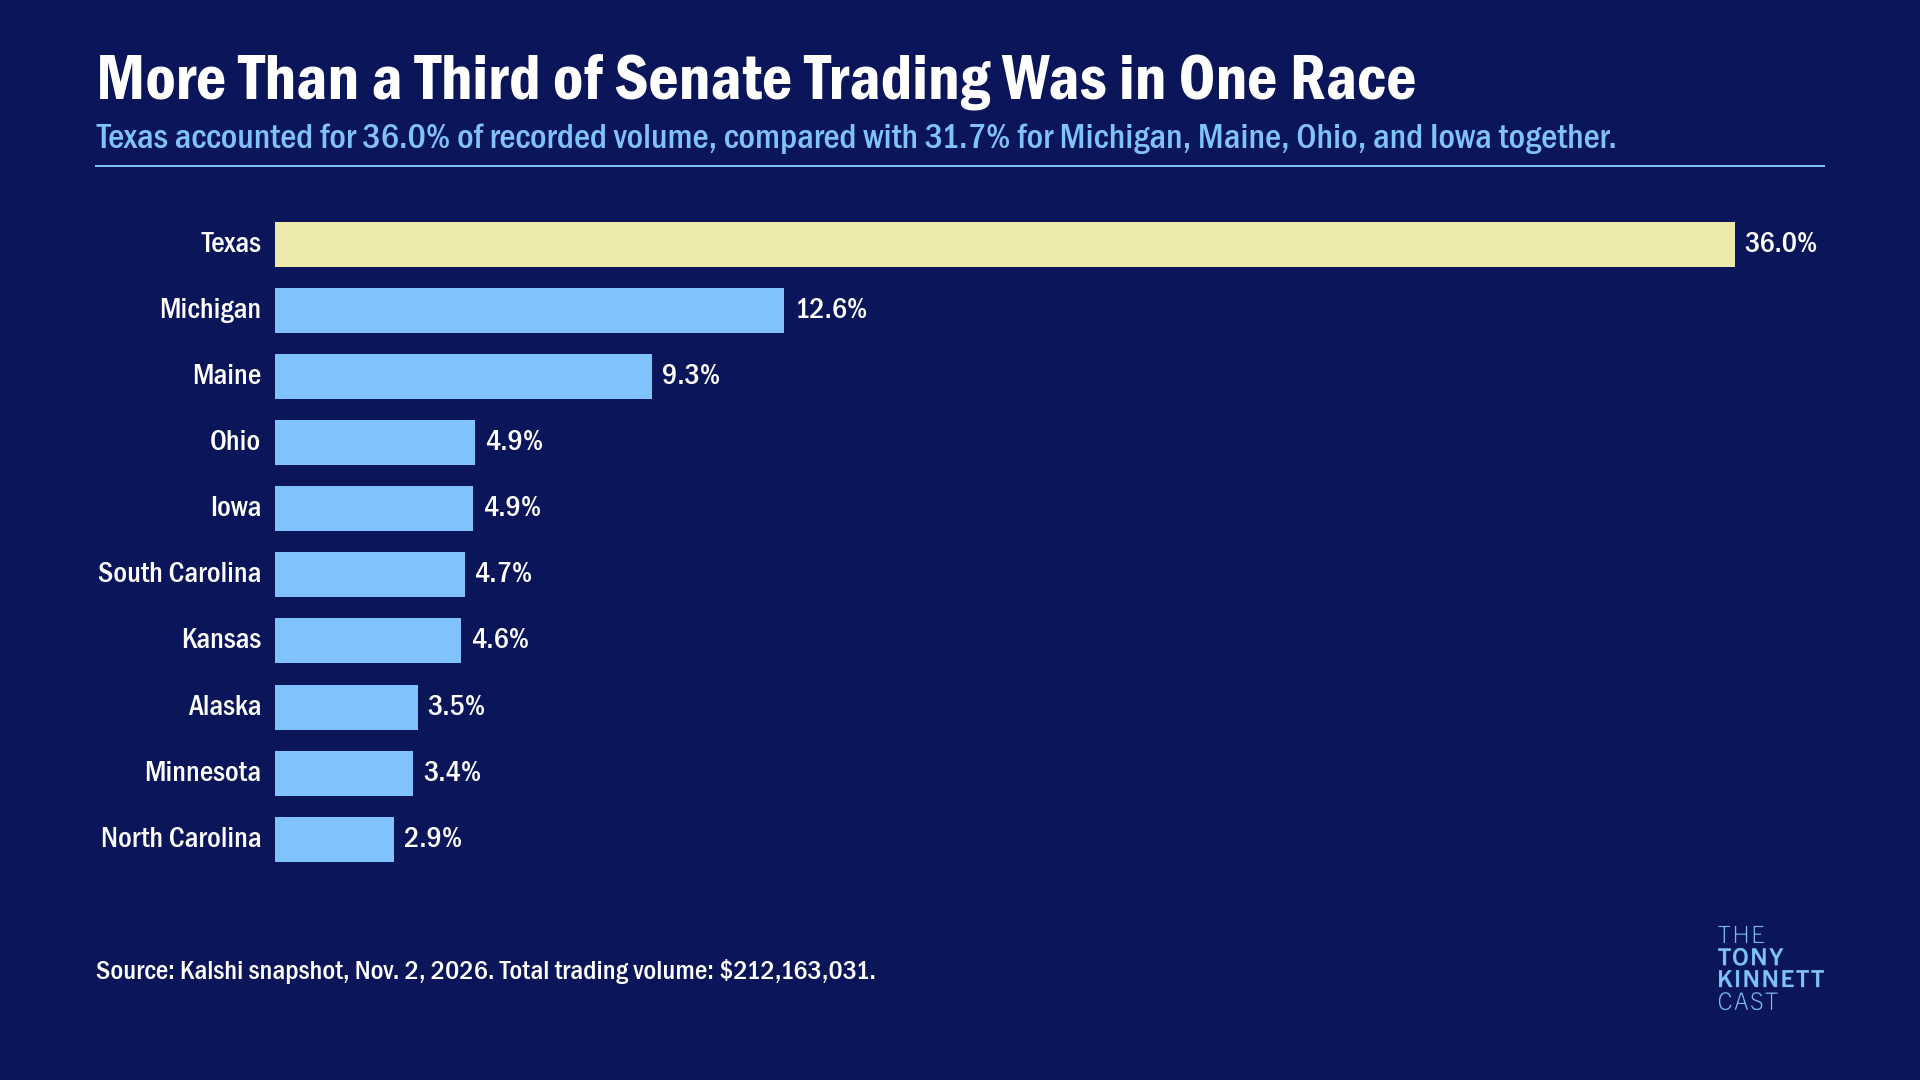

In [3]:
ranked["state"] = ranked.index.map(state_name)
save_table("volume_ranked", ranked)
display(ranked.set_index("state"))
volume_bars("02-largest-markets", "More Than a Third of Senate Trading Was in One Race",
            f"Texas accounted for {ranked.share.iloc[0]:.1%} of recorded volume, compared with "
            f"{ranked.share.iloc[1:5].sum():.1%} for Michigan, Maine, Ohio, and Iowa together.",
            ranked.head(10), state_name(leader))

## 3. Low-volume filter

The cutoff excludes markets with less than $250,000 in cumulative trading volume before matching to outcomes. The project owner confirmed that the frozen volume column is in U.S. dollars.

In [4]:
thin_ids = ranked.loc[ranked.volume.lt(VOLUME_CUTOFF)].sort_values("volume", kind="stable").index
thin = ranked.loc[thin_ids].assign(call_eligible=senate.call_eligible)
print(f"The under ${VOLUME_CUTOFF:,.0f} cutoff removes {len(thin)} races with "
      f"${thin.volume.sum():,.0f} in trading volume ({thin.share.sum():.2%} of the field).")
display(thin.set_index("state"))
save_table("volume_cutoff", thin)

The under $250,000 cutoff removes 11 races with $914,519 in trading volume (0.43% of the field).


,volume,share,rank,call_eligible
state,,,,
Alabama,38641.0,0.000182,35,True
Oregon,43264.0,0.000204,34,True
Wyoming,51448.0,0.000242,33,True
Delaware,57602.0,0.000271,32,True
Rhode Island,63978.0,0.000302,31,True
Illinois,64413.0,0.000304,30,True
West Virginia,65050.0,0.000307,29,True
Oklahoma,87366.0,0.000412,28,True
Virginia,95280.0,0.000449,27,True


## 4. Volume-weighted scoring

Each comparison uses the same matched races and weights for both forecasts. The difference is Kalshi loss minus benchmark loss. Negative differences favor Kalshi. Each subset is reweighted independently. Volume weights emphasize the largest markets and can make an estimate hinge on a small number of races. All comparisons are descriptive. Kalshi's recorded price measure is provisional, and the frozen KY-SEN link names a Louisiana contract. The KY sensitivity excludes that race without changing the frozen values.

In [5]:
benchmarks = {"Economist": "p_economist", "Mixed benchmark": "p_model_mean"}
metrics = [("Brier", "brier", True), ("Clipped log loss", "log", True),
           ("Unclipped log loss", "log", False)]
scores, weights, exclusions = [], [], []

def compare(label, benchmark, market, scenario, dropped=()):
    field = senate.drop(index=list(dropped))
    sample = match_sample(field, [market, benchmark, "volume"])
    rows = sample.rows
    eligible_volume = rows.volume.sum()
    rows["_weight"] = rows.volume / eligible_volume if eligible_volume > 0 else np.nan
    excluded = sample.excluded | {race: [scenario] for race in dropped}
    key = {"benchmark": label, "kalshi": market, "scenario": scenario}
    for race, reasons in excluded.items():
        exclusions.append(key | {"race_id": race, "volume": senate.at[race, "volume"],
                                 "reason": "; ".join(reasons)})
    weight_sum = rows._weight.sum()
    if eligible_volume > 0:
        assert np.isclose(weight_sum, 1)
    for race, row in rows.iterrows():
        weights.append(key | {"race_id": race, "volume": row.volume,
                              "normalized_weight": row._weight})
    info = key | {"eligible": len(rows), "eligible_volume": eligible_volume,
                  "excluded_volume": senate.loc[list(excluded), "volume"].sum(),
                  "excluded_races": ", ".join(sorted(excluded)),
                  "weight_sum": weight_sum,
                  "largest_weight": rows._weight.max(),
                  "effective_races": 1 / rows._weight.pow(2).sum() if eligible_volume > 0 else np.nan}
    for metric_name, metric, clip in metrics:
        for weight in (None, "volume"):
            a = b = np.nan
            status = "Unavailable: fewer than two matched races"
            if len(rows) >= 2 and weight and eligible_volume <= 0:
                status = "Unavailable: matched volume is zero"
            elif len(rows) >= 2:
                a, b = (probability_score(rows, source, metric=metric, clip=clip,
                                          weights=weight).value for source in (market, benchmark))
                status = "Available" if np.isfinite([a, b]).all() else "Unavailable: nonfinite loss"
            scores.append(info | {"metric": metric_name,
                                  "weighting": "Volume" if weight else "Equal races",
                                  "kalshi_loss": a if np.isfinite(a) else np.nan,
                                  "benchmark_loss": b if np.isfinite(b) else np.nan,
                                  "difference": a - b if status == "Available" else np.nan,
                                  "status": status})
    return rows

for label, benchmark in benchmarks.items():
    rows = compare(label, benchmark, "p_kalshi", "Full matched sample")
    compare(label, benchmark, "p_kalshi", f"Drop markets under ${VOLUME_CUTOFF:,.0f}", thin_ids)
    compare(label, benchmark, "p_kalshi_normalized", "Normalized Kalshi")
    if len(rows):
        largest_eligible = next(race for race in ranked.index if race in rows.index)
        compare(label, benchmark, "p_kalshi", "Drop largest eligible", [largest_eligible])
    if "KY-SEN" in rows.index:
        compare(label, benchmark, "p_kalshi", "Drop KY-SEN", ["KY-SEN"])

score_table = pd.DataFrame(scores)
weight_table = pd.DataFrame(weights, columns=["benchmark", "kalshi", "scenario", "race_id",
                                              "volume", "normalized_weight"])
exclusion_table = pd.DataFrame(exclusions, columns=["benchmark", "kalshi", "scenario", "race_id",
                                                   "volume", "reason"])
keys = ["benchmark", "metric", "weighting"]
baseline = score_table.loc[score_table.scenario.eq("Full matched sample"),
                           keys + ["difference"]].rename(columns={"difference": "baseline_difference"})
score_table = score_table.merge(baseline, on=keys, validate="many_to_one")
score_table["change_from_baseline"] = score_table.difference - score_table.baseline_difference
sign_changed = (np.sign(score_table.difference) != np.sign(score_table.baseline_difference))
score_table["direction_changed"] = sign_changed.where(score_table.difference.notna()
                                                       & score_table.baseline_difference.notna())
save_table("scores", score_table)
save_table("weights", weight_table)
save_table("score_exclusions", exclusion_table)
display(score_table[["benchmark", "scenario", "metric", "weighting", "eligible",
                     "kalshi_loss", "benchmark_loss", "difference",
                     "change_from_baseline", "direction_changed", "status"]])
display(score_table[["benchmark", "scenario", "eligible", "eligible_volume", "excluded_races",
                     "excluded_volume", "weight_sum", "largest_weight", "effective_races"]].drop_duplicates())
display(exclusion_table)
for label, benchmark in benchmarks.items():
    matched = match_sample(senate, ["p_kalshi", benchmark]).rows
    overlap = thin_ids.intersection(matched.index)
    print(f"{label}: volume cutoff removes {len(overlap)} eligible races "
          f"and ${senate.loc[overlap, 'volume'].sum():,.0f} in trading volume from the matched sample.")

,benchmark,scenario,metric,weighting,eligible,kalshi_loss,benchmark_loss,difference,change_from_baseline,direction_changed,status
0,Economist,Full matched sample,Brier,Equal races,34,0.058557,0.088188,-0.029631,0.000000e+00,False,Available
1,Economist,Full matched sample,Brier,Volume,34,0.090710,0.194322,-0.103612,0.000000e+00,False,Available
2,Economist,Full matched sample,Clipped log loss,Equal races,34,0.197462,0.271836,-0.074374,0.000000e+00,False,Available
3,Economist,Full matched sample,Clipped log loss,Volume,34,0.333446,0.568247,-0.234800,0.000000e+00,False,Available
4,Economist,Full matched sample,Unclipped log loss,Equal races,34,0.197136,0.271836,-0.074700,0.000000e+00,False,Available
5,Economist,Full matched sample,Unclipped log loss,Volume,34,0.333440,0.568247,-0.234807,0.000000e+00,False,Available
6,Economist,"Drop markets under $250,000",Brier,Equal races,23,0.086486,0.130317,-0.043831,-1.420007e-02,False,Available
7,Economist,"Drop markets under $250,000",Brier,Volume,23,0.091116,0.195193,-0.104077,-4.651025e-04,False,Available
8,Economist,"Drop markets under $250,000",Clipped log loss,Equal races,23,0.285771,0.397038,-0.111266,-3.689215e-02,False,Available
9,Economist,"Drop markets under $250,000",Clipped log loss,Volume,23,0.334887,0.570751,-0.235864,-1.063643e-03,False,Available


,benchmark,scenario,eligible,eligible_volume,excluded_races,excluded_volume,weight_sum,largest_weight,effective_races
0,Economist,Full matched sample,34,204718571.0,AK-SEN,7444460.0,1.0,0.373299,5.557369
6,Economist,"Drop markets under $250,000",23,203804052.0,"AK-SEN, AL-SEN, DE-SEN, IL-SEN, MA-SEN, NM-SEN...",8358979.0,1.0,0.374974,5.507902
12,Economist,Normalized Kalshi,34,204718571.0,AK-SEN,7444460.0,1.0,0.373299,5.557369
18,Economist,Drop largest eligible,33,128297252.0,"AK-SEN, TX-SEN",83865779.0,1.0,0.207766,9.676401
24,Economist,Drop KY-SEN,33,204381885.0,"AK-SEN, KY-SEN",7781146.0,1.0,0.373914,5.539188
30,Mixed benchmark,Full matched sample,34,204718571.0,AK-SEN,7444460.0,1.0,0.373299,5.557369
36,Mixed benchmark,"Drop markets under $250,000",23,203804052.0,"AK-SEN, AL-SEN, DE-SEN, IL-SEN, MA-SEN, NM-SEN...",8358979.0,1.0,0.374974,5.507902
42,Mixed benchmark,Normalized Kalshi,34,204718571.0,AK-SEN,7444460.0,1.0,0.373299,5.557369
48,Mixed benchmark,Drop largest eligible,33,128297252.0,"AK-SEN, TX-SEN",83865779.0,1.0,0.207766,9.676401
54,Mixed benchmark,Drop KY-SEN,33,204381885.0,"AK-SEN, KY-SEN",7781146.0,1.0,0.373914,5.539188


,benchmark,kalshi,scenario,race_id,volume,reason
0,Economist,p_kalshi,Full matched sample,AK-SEN,7444460.0,missing y; no verified DDHQ call
1,Economist,p_kalshi,"Drop markets under $250,000",AK-SEN,7444460.0,missing y; no verified DDHQ call
2,Economist,p_kalshi,"Drop markets under $250,000",AL-SEN,38641.0,"Drop markets under $250,000"
3,Economist,p_kalshi,"Drop markets under $250,000",OR-SEN,43264.0,"Drop markets under $250,000"
4,Economist,p_kalshi,"Drop markets under $250,000",WY-SEN,51448.0,"Drop markets under $250,000"
5,Economist,p_kalshi,"Drop markets under $250,000",DE-SEN,57602.0,"Drop markets under $250,000"
6,Economist,p_kalshi,"Drop markets under $250,000",RI-SEN,63978.0,"Drop markets under $250,000"
7,Economist,p_kalshi,"Drop markets under $250,000",IL-SEN,64413.0,"Drop markets under $250,000"
8,Economist,p_kalshi,"Drop markets under $250,000",WV-SEN,65050.0,"Drop markets under $250,000"
9,Economist,p_kalshi,"Drop markets under $250,000",OK-SEN,87366.0,"Drop markets under $250,000"


Economist: volume cutoff removes 11 eligible races and $914,519 in trading volume from the matched sample.
Mixed benchmark: volume cutoff removes 11 eligible races and $914,519 in trading volume from the matched sample.


## 5. Volume and forecast surprise

Surprise is realized Brier loss minus the expected loss under Kalshi's own probability, `p(1 − p)`. Positive values indicate more loss than expected under that forecast. Use ranks to describe the association with log volume. Outcome coverage and the influence of the largest eligible market limit the interpretation.

Surprise coverage: 34/35 races. Excluded Alaska, $7,444,460 in trading volume.
Eligible field: Spearman correlation: −0.56 across 34 races.
Excluding Texas: Spearman correlation: −0.52 across 33 races.


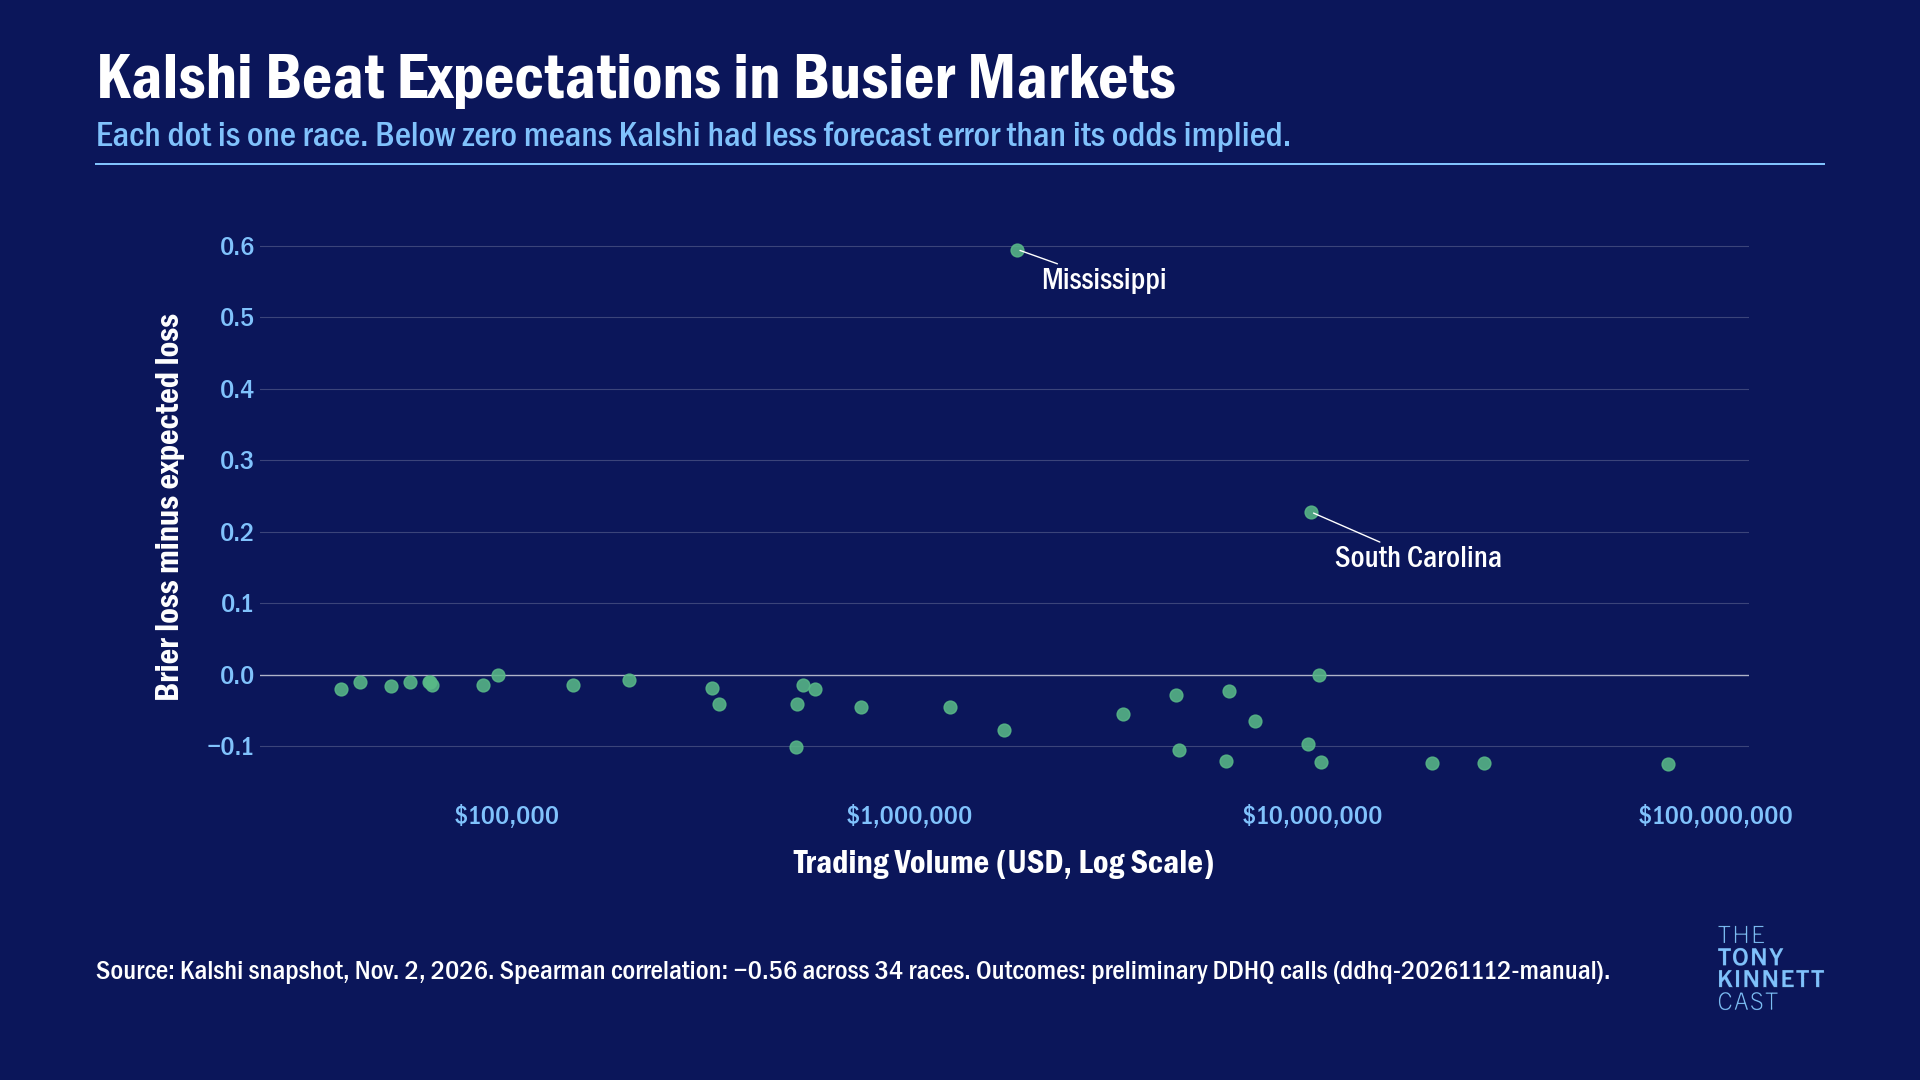

In [6]:
def spearman(x, y):
    if len(x) < 3 or min(x.nunique(), y.nunique()) < 2:
        return np.nan
    return x.rank(method="average").corr(y.rank(method="average"))

def association(rows, column, label):
    coefficient = spearman(rows.log_volume, rows[column])
    text = (f"Spearman correlation: {coefficient:+.2f} across {len(rows)} races.".replace("-", "−")
            if pd.notna(coefficient) else f"Correlation unavailable across {len(rows)} races.")
    print(f"{label}: {text}")
    return text

def scatter(name, title, subtitle, rows, column, ylabel, color, xlim, ylim=None, *,
            footnote, outcome=False, annotations=()):
    source = f"Source: Kalshi snapshot, Nov. 2, 2026. {footnote}"
    if outcome:
        evidence = "synthetic fixture" if synthetic else "preliminary DDHQ calls"
        source += f" Outcomes: {evidence} ({snapshot})."
    canvas = make_canvas(title, subtitle=subtitle, source=source)
    if outcome:
        assert "\n" not in canvas.fig.texts[1].get_text()
    ax = canvas.axes(left_pad=164, right_pad=75, bottom_pad=94, top_pad=26)
    if ylim is None:
        low, high = min(0, rows[column].min()), max(0, rows[column].max())
        padding = max(.01, .07 * (high - low))
        ylim = (low - padding, high + padding)
    ax.set(xlim=xlim, ylim=ylim, xlabel="Trading Volume (USD, Log Scale)", ylabel=ylabel)
    marks = ax.scatter(rows.log_volume, rows[column], color=color, s=85, alpha=.88, zorder=3)
    assert rows.log_volume.between(*xlim).all() and rows[column].between(*ylim).all()
    np.testing.assert_allclose(marks.get_offsets(), rows[["log_volume", column]].to_numpy())
    ax.grid(axis="y", color="white", alpha=.2)
    if outcome:
        ax.axhline(0, color="white", alpha=.6, linewidth=1)
    for race_id in annotations:
        if race_id not in rows.index:
            continue
        point = rows.loc[race_id]
        ax.annotate(state_name(race_id), (point.log_volume, point[column]), xytext=(24, -34 if race_id == "SC-SEN" else -18),
                    textcoords="offset pixels", ha="left", va="top", color="white",
                    fontproperties=canvas.fp("body"), fontsize=22,
                    arrowprops={"arrowstyle": "-", "color": "white", "linewidth": 1})
    ticks = [value for value in range(int(np.ceil(xlim[0])), int(np.floor(xlim[1])) + 1)]
    ax.set_xticks(ticks, [f"${10**value:,.0f}" for value in ticks])
    ymin, ymax = ax.get_ylim()
    ax.set_yticks([tick for tick in ax.get_yticks() if ymin <= tick <= ymax])
    export(canvas, name, rows)

positive = senate.loc[senate.volume.gt(0)].copy()
positive["log_volume"] = np.log10(positive.volume)
xlim = (positive.log_volume.min() - .2, positive.log_volume.max() + .2)
surprise = match_sample(positive, ["p_kalshi"]).rows
surprise["realized_loss"] = brier_loss(surprise.p_kalshi, surprise.y)
surprise["expected_loss"] = surprise.p_kalshi * (1 - surprise.p_kalshi)
surprise["surprise"] = surprise.realized_loss - surprise.expected_loss
omitted = senate.index.difference(surprise.index)
print(f"Surprise coverage: {len(surprise)}/{len(senate)} races. "
      f"Excluded {', '.join(map(state_name, omitted)) or 'none'}, "
      f"${senate.loc[omitted, 'volume'].sum():,.0f} in trading volume.")
footnote = association(surprise, "surprise", "Eligible field")
if len(surprise):
    largest_eligible = next(race for race in ranked.index if race in surprise.index)
    association(surprise.drop(largest_eligible), "surprise", f"Excluding {state_name(largest_eligible)}")
if len(surprise) >= 3:
    annotations = [race_id for race_id in ('MS-SEN', 'SC-SEN') if race_id in surprise.index] if not synthetic else []
    scatter("03-volume-surprise", "Kalshi Beat Expectations in Busier Markets",
            "Each dot is one race. Below zero means Kalshi had less forecast error than its odds implied.",
            surprise[["volume", "log_volume", "p_kalshi", "y", "realized_loss", "expected_loss", "surprise"]],
            "surprise", "Brier loss minus expected loss", colors["kalshi"], xlim,
            footnote=footnote, outcome=True, annotations=annotations)

## 6. Volume and market–model gaps

The Economist comparison is the cleaner benchmark for assessing agreement with Kalshi. VoteHub Complete uses Kalshi order-book data alongside other inputs, with varying market influence across races. The fixed Economist/VoteHub Complete mean therefore has indirect Kalshi exposure. Both comparisons describe agreement among recorded forecasts and can be calculated before results are available.

Economist: excluded none, $0 in trading volume.
Economist: Spearman correlation: +0.83 across 35 races.


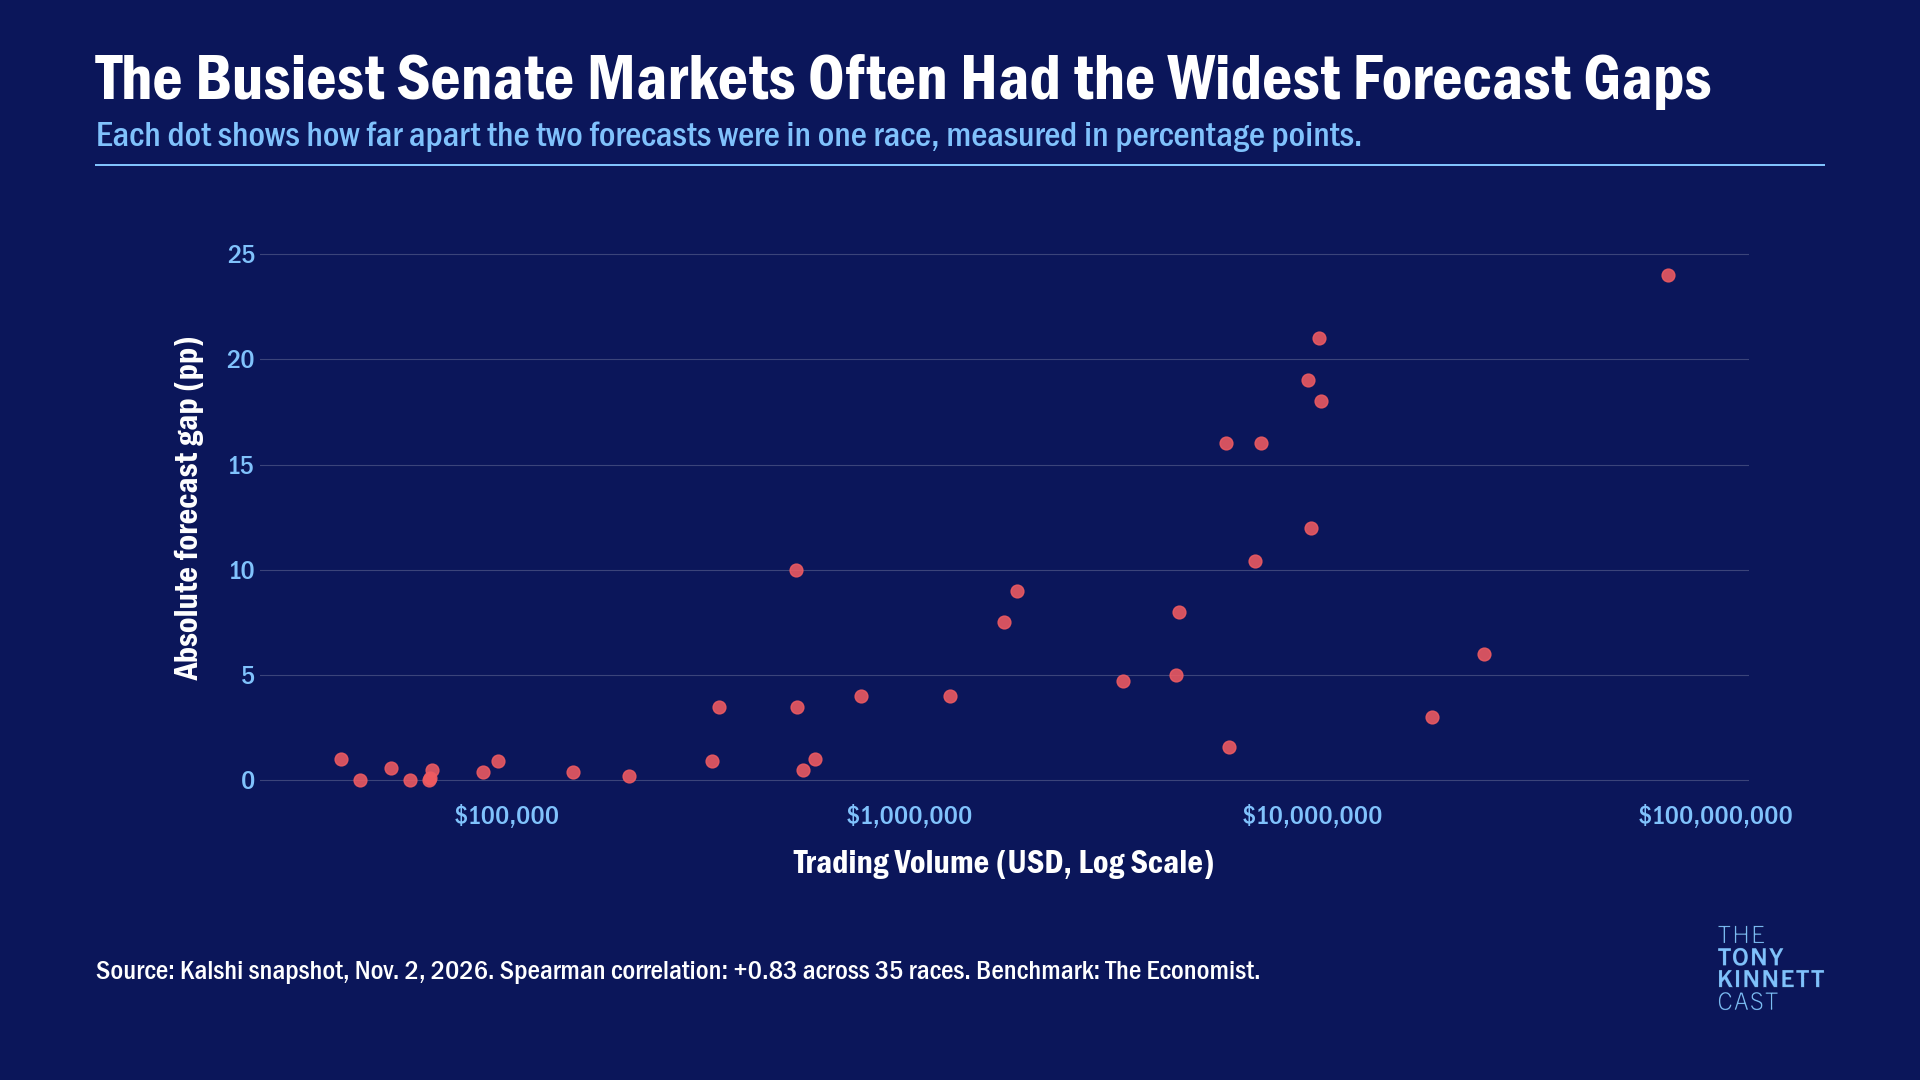

Mixed benchmark: excluded none, $0 in trading volume.
Mixed benchmark: Spearman correlation: +0.73 across 35 races.


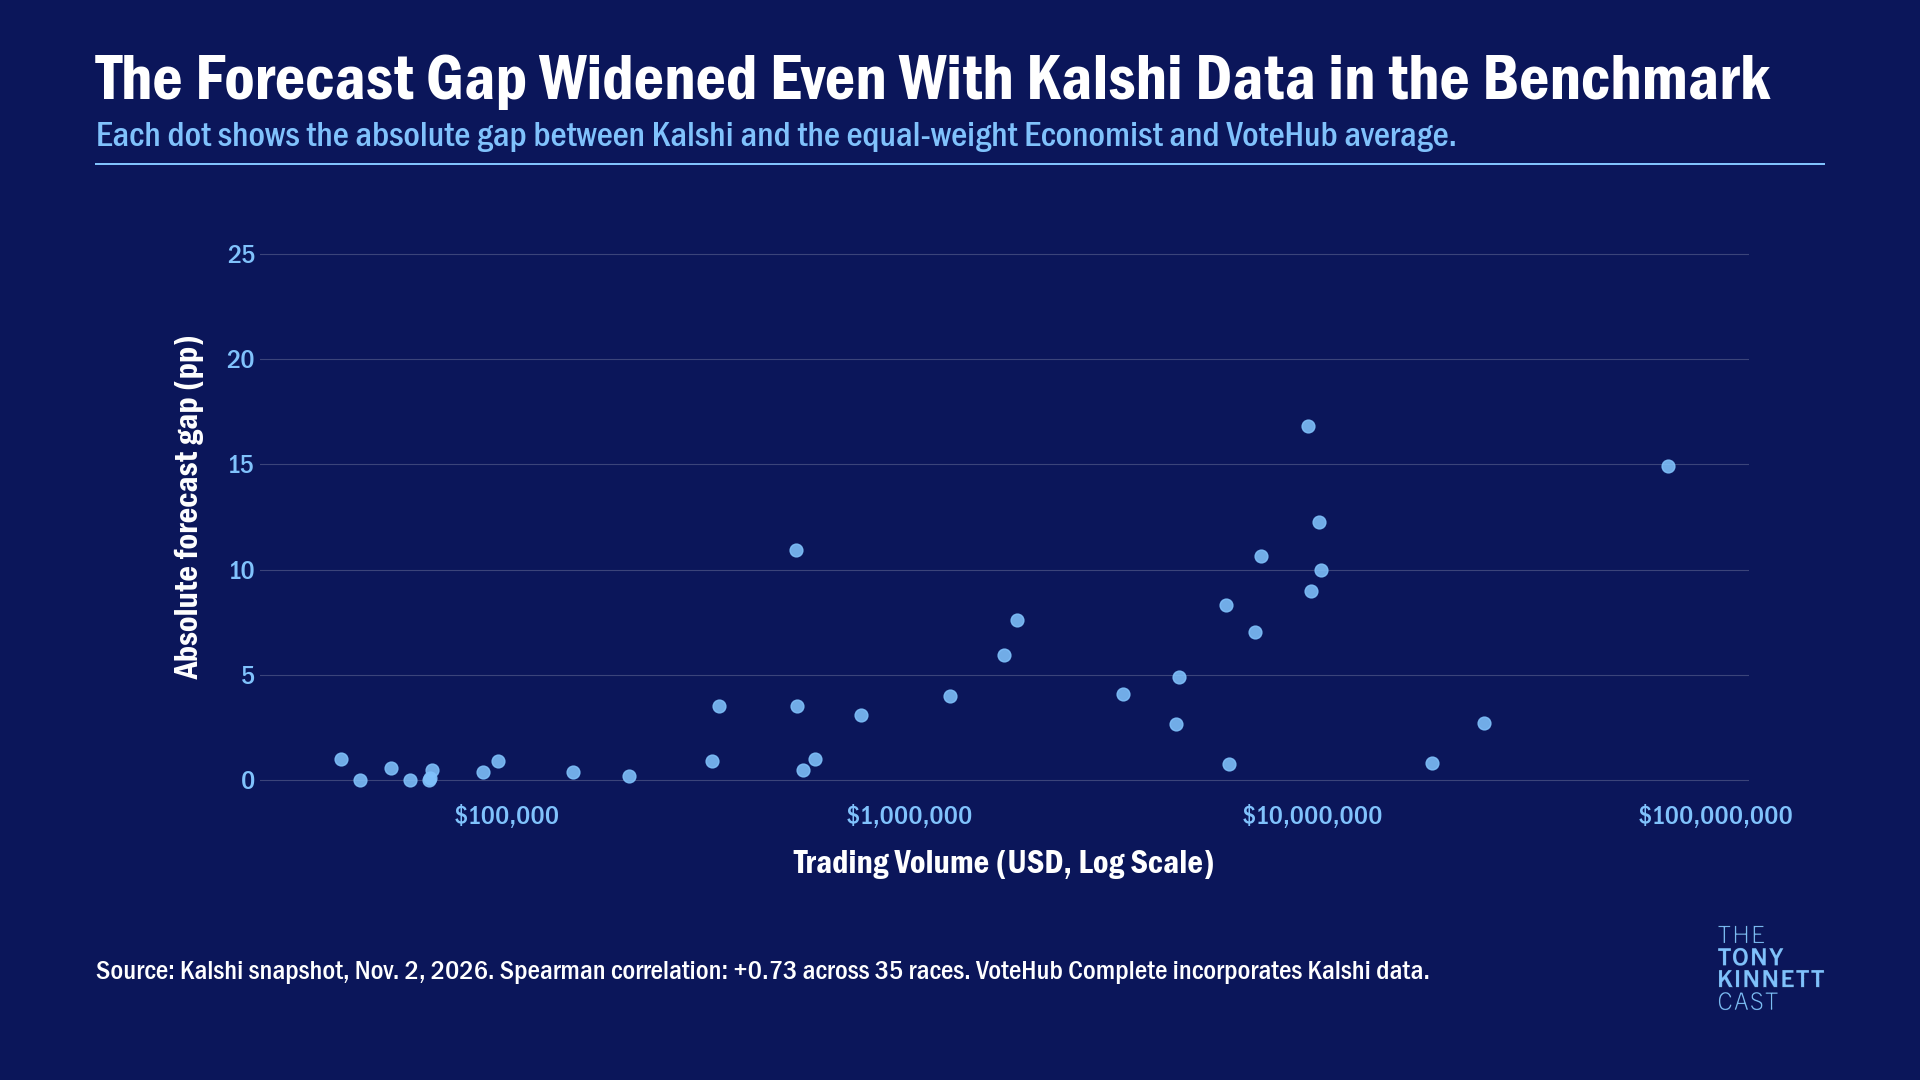

In [7]:
gaps = {}
for label, benchmark in benchmarks.items():
    rows = positive[["volume", "log_volume", "p_kalshi", benchmark]].dropna().copy()
    rows["gap_pp"] = 100 * (rows.p_kalshi - rows[benchmark]).abs()
    gaps[label] = rows
shared = gaps["Economist"].index.intersection(gaps["Mixed benchmark"].index)
upper = max((rows.gap_pp.max() for rows in gaps.values() if len(rows)), default=0) * 1.12
for name, (label, rows) in zip(("04-gap-economist", "05-gap-mixed"), gaps.items()):
    excluded = senate.index.difference(rows.index)
    print(f"{label}: excluded {', '.join(map(state_name, excluded)) or 'none'}, "
          f"${senate.loc[excluded, 'volume'].sum():,.0f} in trading volume.")
    footnote = association(rows, "gap_pp", label)
    if len(shared) != len(rows) or len(shared) != max(map(len, gaps.values())):
        association(rows.loc[shared], "gap_pp", f"{label}, common sample")
    if len(rows):
        if label == "Economist":
            title = "The Busiest Senate Markets Often Had the Widest Forecast Gaps"
            subtitle = "Each dot shows how far apart the two forecasts were in one race, measured in percentage points."
            footnote += " Benchmark: The Economist."
            color = colors["economist"]
        else:
            title = "The Forecast Gap Widened Even With Kalshi Data in the Benchmark"
            subtitle = "Each dot shows the absolute gap between Kalshi and the equal-weight Economist and VoteHub average."
            footnote += " VoteHub Complete incorporates Kalshi data."
            color = colors["model_mean"]
        scatter(name, title, subtitle, rows, "gap_pp", "Absolute forecast gap (pp)", color, xlim,
                (-max(1, upper) * .035, max(1, upper)), footnote=footnote)

hashes = {}
for record in figures:
    for key, directory in (("image", ctx.figures_dir), ("data", ctx.tables_dir)):
        filename = record[key]
        hashes[filename] = sha256(directory / filename)
write_manifest(ctx.tables_dir / "analysis-provenance.json", {
    "snapshot": snapshot, "synthetic": synthetic,
    "senate_timestamp": inputs.manifest["senate_timestamp"],
    "house_timestamp": inputs.manifest["house_timestamp"],
    "input_hashes": inputs.hashes, "graphics_assets": graphics_assets(),
    "editable_source": f"notebooks/{PART}.ipynb", "figures": figures, "artifact_hashes": hashes,
    "volume_units": VOLUME_UNITS, "volume_unit_evidence": VOLUME_UNIT_EVIDENCE,
    "volume_cutoff": VOLUME_CUTOFF, "recorded_volume": int(total),
    "eligible_senate_calls": coverage,
})